In [1]:
import numpy as py
import pandas as pd
import seaborn as sns

In [2]:
pd.__version__

'3.0.6'

In [3]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

In [5]:
df.head(5)

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [5]:
len(df)

10000

In [6]:
df['fuel_type'].nunique()

3

In [7]:
df.isnull()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
9995,False,False,False,False,False,False,False,False,False,False,False
9996,False,False,False,False,False,False,False,False,False,False,False
9997,False,False,False,False,False,False,False,False,False,False,False
9998,False,False,False,False,False,False,False,False,False,False,False


In [13]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [17]:
df[df['origin']=='Asia']['fuel_efficiency_mpg'].max()

np.float64(41.2)

In [18]:
df['horsepower'].median()

np.float64(254.0)

In [19]:
df['horsepower'].isnull().sum()

np.int64(877)

In [20]:
df['horsepower'].mode()

0    252.0
Name: horsepower, dtype: float64

In [26]:
df['horsepower'].value_counts()

horsepower
252.0    174
246.0    168
256.0    168
259.0    165
253.0    165
        ... 
322.0      1
330.0      1
175.0      1
178.0      1
320.0      1
Name: count, Length: 153, dtype: int64

In [30]:
df['horsepower'] = df['horsepower'].fillna(252);

In [32]:
df['horsepower'].median()

np.float64(252.0)

In [31]:
df['horsepower'].isnull().sum()

np.int64(0)

In [9]:
"""
1 - Select all the cars from Asia
2 - Select only columns vehicle_weight and model_year
3 - Select the first 7 values
4 - Get the underlying NumPy array. Let's call it X.
5 - Compute matrix-matrix multiplication between the transpose of X and X. To get the transpose, use X.T. Let's call the result XTX.
6 - Invert XTX.
7 - Create an array y with values [1100, 1300, 800, 900, 1000, 1100, 1200].
8 - Multiply the inverse of XTX with the transpose of X, and then multiply the result by y. Call the result w.
9 - What's the sum of all the elements of the result?

w = (XtX)-1.Xt.y   t=transpose
"""
#asia = df[df['origin']=='Asia']
#x = asia.iloc[:7][['vehicle_weight','model_year']]
x = df.loc[df['origin']=='Asia',['vehicle_weight','model_year']].head(7)
x

,vehicle_weight,model_year
2,4240,1996
6,4310,1992
8,4230,1997
10,4420,1978
15,3950,2007
16,4750,2021
22,4450,2019


In [10]:
z = x.to_numpy()
z

array([[4240, 1996],
       [4310, 1992],
       [4230, 1997],
       [4420, 1978],
       [3950, 2007],
       [4750, 2021],
       [4450, 2019]])

In [11]:
y = py.array([1100, 1300, 800, 900, 1000, 1100, 1200])

In [12]:
z.T

array([[4240, 4310, 4230, 4420, 3950, 4750, 4450],
       [1996, 1992, 1997, 1978, 2007, 2021, 2019]])

In [14]:
XTX = z.T.dot(z)
XTX

array([[131950500,  60750580],
       [ 60750580,  28041424]])

In [16]:
xtx_inv = py.linalg.inv(XTX)
xtx_inv

array([[ 2.96830537e-06, -6.43071025e-06],
       [-6.43071025e-06,  1.39675281e-05]])

In [17]:
w = xtx_inv.dot(z.T).dot(y)
#w = xtx_inv @ z.T @ y

In [18]:
w.sum()

np.float64(0.36919696904925486)

In [19]:
w

array([0.13644777, 0.2327492 ])

In [24]:
(4420*w[0])+(1978*w[1])

np.float64(1063.4770484129153)

In [25]:
x.dot(w)

2     1043.105936
6     1051.726283
8     1041.974208
10    1063.477048
15    1006.096325
16    1118.513027
22    1077.113199
dtype: float64

In [28]:
res = pd.DataFrame({'Actual Cost':y,'Predicted Cost':x.dot(w), 'Difference': y-x.dot(w)})
res

,Actual Cost,Predicted Cost,Difference
2,1100,1043.105936,56.894064
6,1300,1051.726283,248.273717
8,800,1041.974208,-241.974208
10,900,1063.477048,-163.477048
15,1000,1006.096325,-6.096325
16,1100,1118.513027,-18.513027
22,1200,1077.113199,122.886801


In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

Text(0.5, 0, 'Year Built')

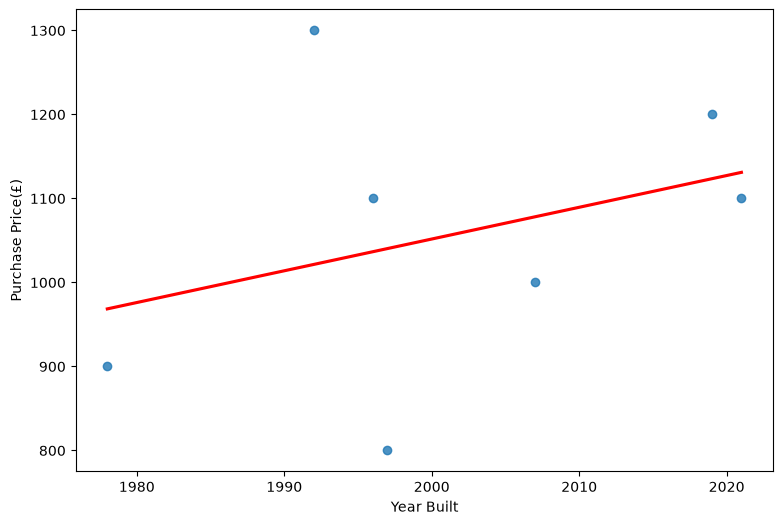

In [41]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.regplot(
    x=z[:, 1],       # 1 Build year, 0 Vehicle weight
    y=y,             # Actual car prices
    ci=None,         # Remove confidence interval
    line_kws={"color": "red"},
    ax=ax
)

ax.set_ylabel("Purchase Price(£)")
ax.set_xlabel("Year Built")

<Axes: xlabel='Actual Cost', ylabel='Predicted Cost'>

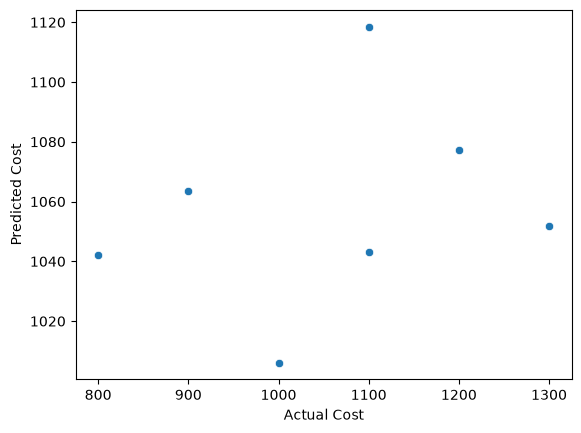

In [31]:
sns.scatterplot(res,x="Actual Cost", y="Predicted Cost")